# Phân tích dữ liệu

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("diabetes_100k.csv")
data.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


In [62]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   year                  100000 non-null  int64  
 1   gender                100000 non-null  object 
 2   age                   100000 non-null  float64
 3   location              100000 non-null  object 
 4   race:AfricanAmerican  100000 non-null  int64  
 5   race:Asian            100000 non-null  int64  
 6   race:Caucasian        100000 non-null  int64  
 7   race:Hispanic         100000 non-null  int64  
 8   race:Other            100000 non-null  int64  
 9   hypertension          100000 non-null  int64  
 10  heart_disease         100000 non-null  int64  
 11  smoking_history       100000 non-null  object 
 12  bmi                   100000 non-null  float64
 13  hbA1c_level           100000 non-null  float64
 14  blood_glucose_level   100000 non-null  int64  
 15  d

In [63]:
data.describe()

,year,age,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,bmi,hbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,2018.360820,41.885856,0.202230,0.200150,0.198760,0.19888,0.199980,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,1.345239,22.516840,0.401665,0.400114,0.399069,0.39916,0.399987,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,2015.000000,0.080000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,2019.000000,24.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,2019.000000,43.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,2019.000000,60.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,2022.000000,80.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [64]:
data['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

In [65]:
data['gender'].value_counts()

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

In [66]:
print(f"Percentage of females: {(58552/100000)*100:.2f}%")
print(f"Percentage of males: {(41430/100000)*100:.2f}%")
print(f"Percentage of other: {(18/100000)*100:.2f}%")

Percentage of females: 58.55%
Percentage of males: 41.43%
Percentage of other: 0.02%


In [67]:
data[['race:AfricanAmerican', 'race:Asian', 'race:Caucasian', 'race:Hispanic', 'race:Other']].sum()

race:AfricanAmerican    20223
race:Asian              20015
race:Caucasian          19876
race:Hispanic           19888
race:Other              19998
dtype: int64

# Biểu đồ

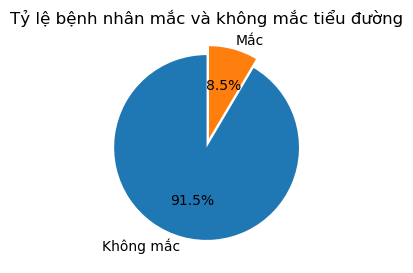

In [8]:
import matplotlib.pyplot as plt

counts = data["diabetes"].value_counts()

plt.figure(figsize=(3, 3))
plt.pie(
    counts,
    labels=["Không mắc", "Mắc"],
    autopct="%1.1f%%",
    startangle=90,
    explode=[0, 0.1]
)

plt.title("Tỷ lệ bệnh nhân mắc và không mắc tiểu đường")
plt.show()

<Axes: xlabel='gender', ylabel='count'>

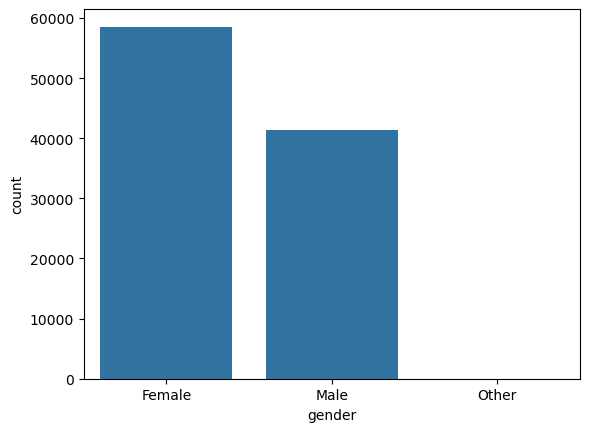

In [9]:
sns.countplot(data=data, x='gender', order=data['gender'].value_counts().index)

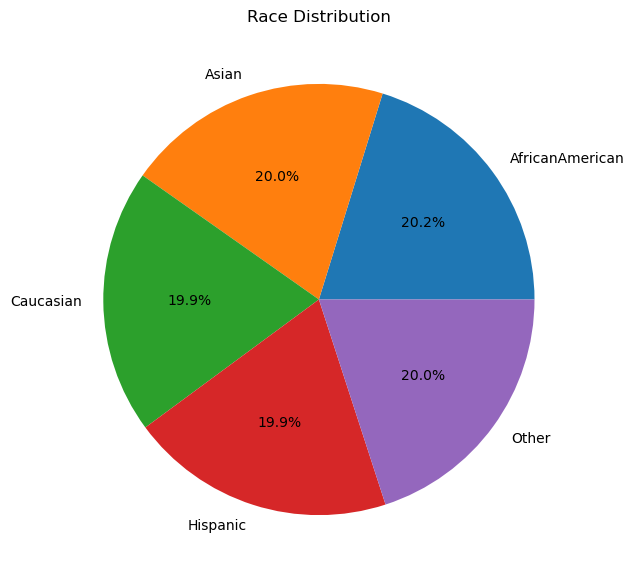

In [10]:
race_data = data.loc[:, data.columns.str.contains('race')]

race_counts = race_data.sum()
race_counts.index = race_counts.index.str.replace('race:', '', regex=False)

race_counts.plot.pie(
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.ylabel('')
plt.title('Race Distribution')
plt.show()

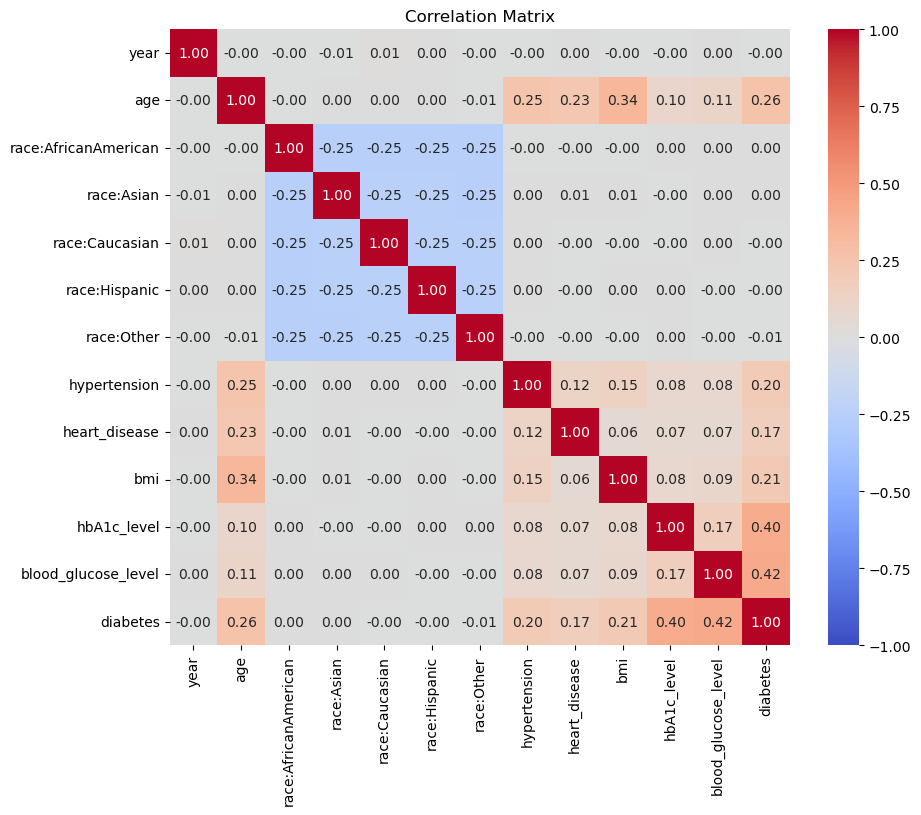

In [11]:
# Correlation between features
corr = data.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.show()

# Tiền xử lý dữ liệu

In [68]:
data = data.drop(columns=['year', 'location'])

X = data.loc[:, data.columns != 'diabetes'] # Input features
y = data['diabetes'] # Output labels


categorical_features=["gender", "smoking_history"]
numeric_features = [col for col in X.columns
                    if col not in categorical_features]

feature_names = X.columns.tolist()

In [69]:
# export cho DL trước xử lí
import joblib
joblib.dump(
    (
        X, y,
        numeric_features, categorical_features
    ), "dl_data.pkl"
)

['dl_data.pkl']

In [70]:
# Check for null/empty cells
data.isnull().sum()

gender                  0
age                     0
race:AfricanAmerican    0
race:Asian              0
race:Caucasian          0
race:Hispanic           0
race:Other              0
hypertension            0
heart_disease           0
smoking_history         0
bmi                     0
hbA1c_level             0
blood_glucose_level     0
diabetes                0
dtype: int64

In [71]:
from sklearn.model_selection import train_test_split

# Split dataset into 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=.2, stratify = y,
        random_state=42, shuffle = True
    )

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((80000, 13), (20000, 13), (80000,), (20000,))

In [72]:
X_train = pd.get_dummies(
    X_train,
    columns=['gender', 'smoking_history'],
    dtype=int
)
X_test = pd.get_dummies(
    X_test,
    columns=['gender', 'smoking_history'],
    dtype=int
)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [73]:
# Scale Features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Mô hình

In [75]:
from sklearn.model_selection import cross_val_score
from sklearn import metrics

def drawCrossChart(range_list, model_func, xlabel, title):
    scores = []

    for r in range_list:
        model = model_func(r)

        s = cross_val_score(
            model, X_train, y_train,
            scoring='accuracy', cv=5
        )

        print(f"Parameter={r}: Accuracy={np.mean(s):.4f}")
        scores.append(np.mean(s))

    plt.figure(figsize=(8, 5))
    plt.plot(range_list, scores, marker='o')
    plt.xlabel(xlabel)
    plt.ylabel("Cross-validation Accuracy")
    plt.title(title)
    plt.show()

## 1. Logistic Regression

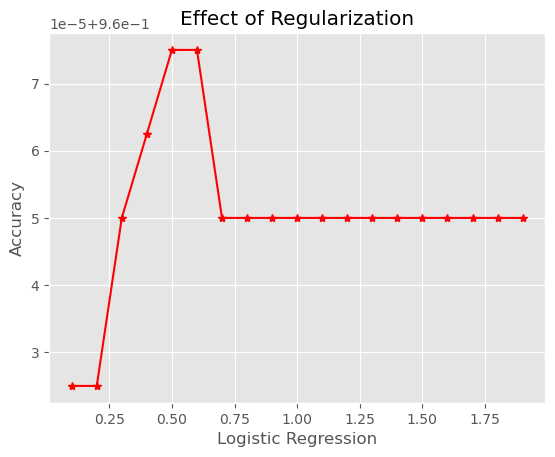

In [19]:
from sklearn.linear_model import LogisticRegression

rgl_values = np.arange(0.1, 2, 0.1)
drawCrossChart(
    range_list = rgl_values,
    model_func=lambda r: LogisticRegression(C=r),
    xlabel="Logistic Regression",
    title="Effect of Regularization"
)

In [76]:
from sklearn.linear_model import LogisticRegression
logr = LogisticRegression(C=0.5)
logr.fit(X_train, y_train)
y_pred = logr.predict(X_test)

print(
    f"Model Accuracy: "
    f"{metrics.accuracy_score(y_test, y_pred)*100:.2f}%"
)

Model Accuracy: 96.06%


## 2. Decision Tree

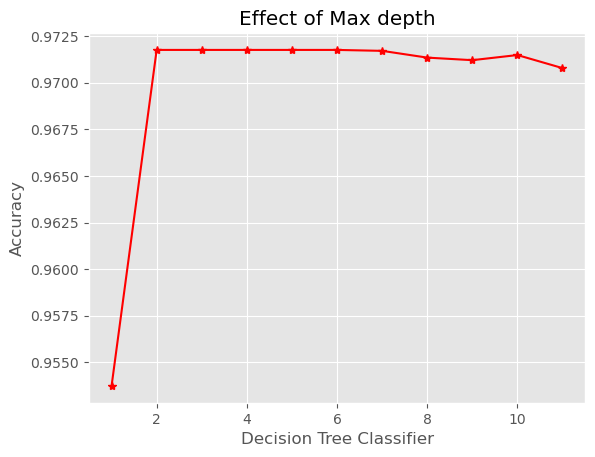

In [23]:
from sklearn.tree import DecisionTreeClassifier

d_values = list(range(1, 12))
drawCrossChart(
    range_list = d_values,
    model_func=lambda r: DecisionTreeClassifier(max_depth=r),
    xlabel="Decision Tree Classifier",
    title="Effect of Max depth"
)


In [79]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

print(
    f"Model Accuracy: "
    f"{metrics.accuracy_score(y_test, y_pred)*100:.2f}%"
)

Model Accuracy: 97.23%


## 3.Random Forest Classifier

In [80]:
from sklearn.ensemble import RandomForestClassifier

min_leaf_values = [1, 2, 4, 5, 6]
drawCrossChart(
    range_list = min_leaf_values,
    model_func=lambda r: RandomForestClassifier(min_samples_leaf=r, n_jobs=-1),
    xlabel="Random Forest Classifier",
    title="Effect of Min samples leaf values"
)


KeyboardInterrupt: 

In [81]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(min_samples_leaf=4)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print(
    f"Model Accuracy: "
    f"{metrics.accuracy_score(y_test, y_pred)*100:.2f}%"
)

Model Accuracy: 97.25%


## 4. Deep Learning

In [ ]:
stop=

In [82]:
dl_res = joblib.load("dl_result.pkl")

# So sánh model

In [ ]:
from sklearn import metrics

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred,zero_division=0)
    recall = recall_score(y_test, y_pred,zero_division=0)
    f1 = f1_score(y_test, y_pred,zero_division=0)
    auc = roc_auc_score(y_test,y_score)

    cm = confusion_matrix(y_test, y_pred)

    return {
        'Model': name,
        'Accuracy': acc, 'Precision': precision,
        'Recall': recall, 'F1-score': f1,
        'ROC-AUC': auc, 'Confusion Matrix': cm
    }

In [84]:
#baseline
from sklearn.dummy import DummyClassifier
baseline = DummyClassifier(strategy ="most_frequent")
baseline.fit(X_train , y_train)

,strategy,'most_frequent'
,random_state,None
,constant,None


In [87]:
results = []

model_list = [
    ('Baseline', baseline),
    ('Logistic Regression', logr),
    ('Decision Tree', dt),
    ('Random Forest', rf)
]

for name, model in model_list:

    result = evaluate_model(
        name,
        model,
        X_test,
        y_test
    )

    results.append(result)

# Add kq của DL
results.append(dl_res)

In [86]:
res_df = pd.DataFrame(results).set_index('Model')

res_df.sort_values(
    by='Accuracy',
    ascending=False
)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Confusion Matrix
Model,,,,,,
Random Forest,0.97250,0.997405,0.678235,0.807423,0.969005,"[[18297, 3], [547, 1153]]"
Decision Tree,0.97230,1.000000,0.674118,0.805341,0.837059,"[[18300, 0], [554, 1146]]"
Deep Learning 5 Layers,0.96430,0.891978,0.660200,0.758784,0.965795,"[[18163, 578], [136, 1123]]"
Logistic Regression,0.96055,0.865277,0.634706,0.732270,0.961782,"[[18132, 168], [621, 1079]]"
Baseline,0.91500,0.000000,0.000000,0.000000,0.500000,"[[18300, 0], [1700, 0]]"


# Triển khai

In [40]:
# Tính giá trị trung bình của các feature dạng số
non_diabetic = data[data["diabetes"] == 0]
reference_means = non_diabetic[['age', 'bmi', 'hbA1c_level', 'blood_glucose_level']].mean()

print(reference_means)

age                     40.115187
bmi                     26.887163
hbA1c_level              5.396761
blood_glucose_level    132.852470
dtype: float64


In [44]:
import joblib

joblib.dump(
    {
        "model": rf,
        "scaler": scaler,
        "feature_names": feature_names,
        "reference_means": reference_means
    },
    "rf_diabetes.pkl"
)

['rf_diabetes.pkl']